# M2: iterate over δ

In [ ]:
from WERM.signal_priors import SparseGaussianSignal, SparseDiffSignal
import WERM.model
import WERM.performance_measures
import importlib
import WERM.comparison
importlib.reload(WERM.comparison)
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm
import time
from joblib import Parallel, delayed
import logging
from datetime import datetime, timedelta
import sys
import pickle

# Set a random seed for reproducibility
random_seed = 42
nprandom.seed(random_seed)

# --- Logging Setup ---
def setup_logging():
    """Setup comprehensive logging for the simulation"""
    detailed_formatter = logging.Formatter(
        '%(asctime)s - %(name)s - %(levelname)s - %(message)s',
        datefmt='%Y-%m-%d %H:%M:%S'
    )
    simple_formatter = logging.Formatter(
        '%(asctime)s - %(message)s',
        datefmt='%H:%M:%S'
    )

    main_logger = logging.getLogger('simulation')
    main_logger.setLevel(logging.INFO)

    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(simple_formatter)
    main_logger.addHandler(console_handler)

    file_handler = logging.FileHandler('logs/M1a_simulation_detailed.log', mode='w')
    file_handler.setLevel(logging.DEBUG)
    file_handler.setFormatter(detailed_formatter)
    main_logger.addHandler(file_handler)

    progress_logger = logging.getLogger('progress')
    progress_logger.setLevel(logging.INFO)

    progress_handler = logging.FileHandler('logs/M1a_simulation_progress.log', mode='w')
    progress_handler.setLevel(logging.INFO)
    progress_handler.setFormatter(detailed_formatter)
    progress_logger.addHandler(progress_handler)

    return main_logger, progress_logger

# Initialize loggers
main_logger, progress_logger = setup_logging()

class ProgressTracker:
    """Class to track and log simulation progress"""
    def __init__(self, total_tasks, varying_param_list, num_trials, logger, param_name="delta"):
        self.total_tasks = total_tasks
        self.varying_param_list = varying_param_list
        self.num_trials = num_trials
        self.logger = logger
        self.start_time = time.time()
        self.completed_tasks = 0
        self.param_progress = {i: 0 for i in range(len(varying_param_list))}
        self.param_name = param_name

    def update(self, param_idx):
        """Update progress for a completed task"""
        self.completed_tasks += 1
        percent_complete = (self.completed_tasks / self.total_tasks) * 100
        elapsed_time = time.time() - self.start_time

        if self.completed_tasks > 0:
            avg_time_per_task = elapsed_time / self.completed_tasks
            remaining_tasks = self.total_tasks - self.completed_tasks
            estimated_remaining_time = remaining_tasks * avg_time_per_task
            estimated_completion = datetime.now() + timedelta(seconds=estimated_remaining_time)

            self.logger.info(
                f"Progress: {self.completed_tasks}/{self.total_tasks} ({percent_complete:.1f}%) | "
                f"Elapsed: {elapsed_time:.1f}s | "
                f"Est. remaining: {estimated_remaining_time:.1f}s | "
                f"Est. completion: {estimated_completion.strftime('%H:%M:%S')}"
            )

        self.param_progress[param_idx] += 1
        if self.completed_tasks % max(1, self.total_tasks // 5) == 0 or self.completed_tasks == 1:
            param_status = []
            for i, param_val in enumerate(self.varying_param_list):
                progress = self.param_progress[i]
                param_status.append(f"{self.param_name}={param_val:.1f}: {progress}/{self.num_trials}")
            self.logger.info(f"{self.param_name.capitalize()} progress: " + " | ".join(param_status))

# Global progress tracker (initialized later)
progress_tracker = None

# --- Helper Function for a Single Parallel Job ---
def run_single_trial(params, p, L, fixed_noise_scale, fractional_chgpt_locations, M, gamma_candidates, method_configs):
    """
    Executes a single simulation trial for a given delta, running multiple methods.
    This function is designed to be called in parallel by joblib.
    """
    global progress_tracker
    i, delta, j = params # delta is now the iterating parameter
    trial_start_time = time.time()

    progress_logger.info(f"Starting trial {j+1}/{num_trials} for delta={delta:.1f} (delta_idx={i})")

    # --- Setup based on delta and fixed noise_scale ---
    n = int(delta * p)
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    # Sparse Difference Signal Prior
    α = 0.5 # fraction of nonzeros in change vector
    var_β_1 = 8
    σ_w = np.sqrt(400*delta) # standard deviation of the signal perturbation
    signal_prior = SparseDiffSignal(var_β_1, σ_w, α, L)

    # --- Data Generation for this trial ---
    data_gen_start = time.time()
    B̃ = signal_prior.sample(p)
    # print("B̃ shape:", B̃.shape) # Keep for debugging if needed
    X = nprandom.normal(0, np.sqrt(1/n), (n, p))
    ε = nprandom.normal(0, 1, size=(n,)) * fixed_noise_scale # Using fixed_noise_scale here

    r = 0.0 # Charcoal requires i.i.d covariates
    Sigma = np.eye(p)
    for i_cov in range(p):
        for j_cov in range(p):
            if i_cov != j_cov:
                Sigma[i_cov, j_cov] = np.power(r, abs(i_cov - j_cov))

    X = X @ np.linalg.cholesky(Sigma).T
    true_chgpts = true_chgpt_locations_fn(n)
    C_true = η_to_ψ(true_chgpts, n) if true_chgpts.size > 0 else np.zeros(n).astype(int)

    X_scaled = X * np.sqrt(n)
    B̃_scaled = B̃ / np.sqrt(n)
    Θ = X_scaled @ B̃_scaled
    y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
    data_gen_time = time.time() - data_gen_start

    # --- Run Estimators for all configured methods ---
    trial_results = {}
    methods_status = {method_name: False for method_name in method_configs.keys()}

    for method_name, method_func_info in method_configs.items():
        try:
            # print(f"Running {method_name} on params: ", params) # Keep for debugging if needed
            method_start = time.time()
            cp = np.array([]) # Initialize changepoints

            if method_name == 'McScan':
                # print(f"Input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).shape}") # Keep for debugging if needed
                # print(f"New input shapes: X_scaled: {np.array(X_scaled).shape}, y: {np.array(y).reshape((n, 1)).shape}") # Keep for debugging if needed
                cp = np.asarray(WERM.comparison.run_mcscan(np.array(X_scaled), np.array(y).flatten(), num_chgpts = None, method='auto'))
                # print(f"McScan res: {cp}") # Keep for debugging if needed
            elif method_name == 'DCDP':
                cp = np.array([-1]) # Placeholder for DCDP
                # print(f"True changepoints: {true_chgpts}, DCDP changepoints: {cp}") # Keep for debugging if needed
            elif method_name == 'DPDU':
                cp = np.asarray(WERM.comparison.DPDU(np.array(X_scaled), y, λs = [0.01, 0.1, 1, 2], ζs = [10.0, 15.0, 20.0]))
            elif method_name == 'MOSEG':
                res = WERM.comparison.MOSEG(np.array(X_scaled), y, num_chgpts=len(fractional_chgpt_locations))
                cp = res[2]
            elif method_name == 'charcoal':
                cp = WERM.comparison.run_charcoal(np.array(X_scaled), np.array(y), fixed_noise_scale, true_chgpt_locations_fn(n))
            elif method_name == 'WERM-CV':
                Delta = lambda n_len: 1
                # Run cross-validation to find the best regularisation penalty parameter
                def WERM_l1_reg_paramCV(X_train, y_train, l1_reg_param):
                    """Cross-validation function for WERM with L1 regularization, tested for fixed num chgpts."""

                    def P_func_(beta):
                        return l1_reg_param * jnp.sum(jnp.abs(beta))

                    return WERM.estimators.weighted_erm(
                        X=X_train, y=y_train, M=M, L=L, Delta_n=Delta(n), gamma=l1_reg_param,
                        L_is_upper_bound=False, return_B_hat=False,
                        brute_force=False, P_func=P_func_
                    )

                # Perform cross-validation to find the best gamma
                best_l1_reg, best_model_output = WERM.estimators.chgpt_k_fold_cv(
                    f=WERM_l1_reg_paramCV,
                    X=X,
                    y=y,
                    gamma_candidates=[1e-4, 1e-3, 1e-2],
                    M_scorer=M_scorer,
                    P_scorer=None,
                    k=5,
                    n_jobs=1
                )

                P_func = lambda beta: best_l1_reg * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=0.0,
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func
                )
            elif method_name == 'WERM-unp':
                delta_fraction = 1/10
                Delta_n = lambda n_len: int(n_len * delta_fraction) # Example Delta_n function, adjust as needed
                best_L_tilde, cp = WERM.estimators.weighted_erm_num_chgptCV(X=X, y=y, M=M, Delta_n=Delta_n(n), Lmax=L,
                    brute_force=False, return_gof=False, M_scorer=M_scorer,
                    num_folds=5, n_jobs=1
                )
            elif method_name == 'WERM-fixed':
                fixed_gamma_value = 1e-3 # Example fixed gamma value
                P_func_fixed = lambda beta: fixed_gamma_value * jnp.sum(jnp.abs(beta))
                cp = WERM.estimators.weighted_erm(
                    X=X, y=y, M=M, L=L, Delta_n=1, gamma=0.0, # Delta_n=1 is a placeholder, adjust if needed
                    L_is_upper_bound=False, return_B_hat=False,
                    brute_force=False, P_func=P_func_fixed
                )
            else:
                main_logger.warning(f"Method {method_name} not recognized. Skipping.")
                continue

            method_time = time.time() - method_start
            trial_results[f'runtime_{method_name}'] = method_time

            trial_results[f'haus_{method_name}'] = (1/n) * WERM.performance_measures.hausdorff(cp, true_chgpts)

            trial_results[f'size_{method_name}'] = len(cp[cp != -1])
            trial_results[f'chgpts_{method_name}'] = cp.copy()
            methods_status[method_name] = True

        except Exception as e:
            main_logger.error(f"Trial {j+1} for delta={delta:.1f}: {method_name} failed with error: {e}")
            trial_results[f'runtime_{method_name}'] = np.nan
            trial_results[f'haus_{method_name}'] = np.nan
            trial_results[f'size_{method_name}'] = np.nan
            trial_results[f'chgpts_{method_name}'] = np.array([])
            methods_status[method_name] = False

    # Store additional info for histogram plotting
    trial_results['n'] = n
    trial_results['true_chgpts'] = true_chgpts.copy()
    trial_results['fractional_true_chgpts'] = fractional_chgpt_locations.copy()
    trial_results['methods_status'] = methods_status

    trial_total_time = time.time() - trial_start_time
    log_message_parts = [
        f"Completed trial {j+1} for delta={delta:.1f}: ",
        f"Total={trial_total_time:.1f}s (Data={data_gen_time:.1f}s)"
    ]
    for method_name in method_configs.keys():
        status_str = 'OK' if methods_status[method_name] else 'FAIL'
        runtime_str = f"{trial_results[f'runtime_{method_name}']:.1f}s" if f'runtime_{method_name}' in trial_results and not np.isnan(trial_results[f'runtime_{method_name}']) else "N/A"
        log_message_parts.append(f"{method_name}={status_str} ({runtime_str})")
    progress_logger.info(" ".join(log_message_parts))

    if progress_tracker:
        progress_tracker.update(i)

    return i, j, trial_results

# --- Main Script Setup ---
main_logger.info("Starting Changepoint Detection Simulation with flexible methods and enhanced logging")
main_logger.info("=" * 60)

# Simulation Parameters
p = 200
L = 4
fixed_noise_scale = np.sqrt(0.1) # Noise scale is now fixed
delta_list = np.arange(0.5, 5.0, 1.0) # Iterate over delta
num_trials = 30
fractional_chgpt_locations = np.array([0.4, 0.7])
n_jobs = 45

# --- Define Methods to be Evaluated ---
methods_to_evaluate = [
    {'name': 'McScan', 'label': r'\textbf{McScan}', 'color': '#EE7733', 'marker': 'o', 'linestyle': '-'},
    {'name': 'charcoal', 'label': r'\textbf{charcoal}', 'color': '#EE3377', 'marker': '^', 'linestyle': '-.'},
    {'name': 'WERM-unp', 'label': r'\textbf{WERM}', 'color': '#009988', 'marker': '<', 'linestyle': '--'},
]

# Create a dictionary for easy lookup within run_single_trial
method_configs = {method['name']: method for method in methods_to_evaluate}
method_names_list = [m['name'] for m in methods_to_evaluate] # List of just names

# Log simulation parameters
main_logger.info(f"Simulation Parameters:")
main_logger.info(f" p (features): {p}")
main_logger.info(f" L (signals): {L}")
main_logger.info(f" Fixed Noise Scale ($\sigma_{{\\varepsilon}}$): {fixed_noise_scale:.3f}")
main_logger.info(f" δ_list: {delta_list}")
main_logger.info(f" num_trials: {num_trials}")
main_logger.info(f" fractional_chgpt_locations: {fractional_chgpt_locations}")
main_logger.info(f" n_jobs: {n_jobs}")
main_logger.info(f" Methods to evaluate: {method_names_list}")
main_logger.info(f" Total tasks: {len(delta_list) * num_trials}")

# Results Storage
results = {
    'successful_trials': {method['name']: np.zeros(len(delta_list), dtype=int) for method in methods_to_evaluate},
    'true_chgpts': [],
    'n_values': [],
    'delta_values': [] # Renamed from noise_scale_values
}

for method in methods_to_evaluate:
    method_name = method['name']
    results[f'haus_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'size_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'runtime_{method_name}'] = np.full((len(delta_list), num_trials), np.nan)
    results[f'chgpts_{method_name}'] = []

# Loss Function (Least Squares)
M = lambda u, v: jnp.power(u - v, 2)
M_scorer = lambda u, v: jnp.abs(u - v)

# Gamma candidates for cross-validation of WERM
gamma_candidates = np.logspace(-1, 2, 5)

# --- Parallel Execution ---
tasks = [(i, delta, j) for i, delta in enumerate(delta_list) for j in range(num_trials)]
main_logger.info("=" * 60)
main_logger.info(f"Starting {len(tasks)} simulation trials")
main_logger.info(f"Using {n_jobs if n_jobs != -1 else 'all available'} CPU cores")

single_trial_estimate = 30.0 * len(methods_to_evaluate)
total_estimated_time = len(tasks) * single_trial_estimate / (n_jobs if n_jobs > 0 else 4)
estimated_completion = datetime.now() + timedelta(seconds=total_estimated_time)
main_logger.info(f"Estimated total time: {total_estimated_time/60:.1f} minutes")
main_logger.info(f"Estimated completion: {estimated_completion.strftime('%Y-%m-%d %H:%M:%S')}")
main_logger.info("=" * 60)

progress_tracker = ProgressTracker(len(tasks), delta_list, num_trials, main_logger, param_name="delta") # Updated tracker
simulation_start_time = time.time()

try:
    parallel_results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(run_single_trial)(
            params=task,
            p=p,
            L=L,
            fixed_noise_scale=fixed_noise_scale, # Pass fixed noise_scale
            fractional_chgpt_locations=fractional_chgpt_locations,
            M=M,
            gamma_candidates=gamma_candidates,
            method_configs=method_configs
        ) for task in tqdm(tasks, desc="Running simulation trials", ncols=100)
    )
    simulation_end_time = time.time()
    total_simulation_time = simulation_end_time - simulation_start_time
    main_logger.info("=" * 60)
    main_logger.info(f"Simulation completed successfully!")
    main_logger.info(f"Total simulation time: {total_simulation_time/60:.2f} minutes")
    main_logger.info(f"Average time per trial: {total_simulation_time/len(tasks):.2f} seconds")
    main_logger.info("=" * 60)
except Exception as e:
    main_logger.error(f"Simulation failed with error: {str(e)}")
    raise

# --- Aggregate Results ---
main_logger.info("Aggregating results...")
aggregation_start_time = time.time()

for result_idx, (i, j, trial_result) in enumerate(parallel_results):
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        if trial_result['methods_status'][method_name]:
            results[f'haus_{method_name}'][i, j] = trial_result[f'haus_{method_name}']
            results[f'size_{method_name}'][i, j] = trial_result[f'size_{method_name}']
            results[f'runtime_{method_name}'][i, j] = trial_result[f'runtime_{method_name}']
            results['successful_trials'][method_name][i] += 1
        results[f'chgpts_{method_name}'].append((i, trial_result[f'chgpts_{method_name}']))

    results['true_chgpts'].append((i, trial_result['true_chgpts']))
    results['n_values'].append((i, trial_result['n']))
    results['delta_values'].append((i, delta_list[i])) # Store delta

aggregation_time = time.time() - aggregation_start_time
main_logger.info(f"Results aggregation completed in {aggregation_time:.2f} seconds")

# Log summary statistics
main_logger.info("=" * 40)
main_logger.info("SIMULATION SUMMARY STATISTICS")
main_logger.info("=" * 40)
for i, delta_val in enumerate(delta_list):
    main_logger.info(f"δ = {delta_val:.1f}:")
    for method_obj in methods_to_evaluate:
        method_name = method_obj['name']
        avg_haus = np.nanmean(results[f'haus_{method_name}'][i, :])
        std_haus = np.nanstd(results[f'haus_{method_name}'][i, :])
        avg_size = np.nanmean(results[f'size_{method_name}'][i, :])
        std_size = np.nanstd(results[f'size_{method_name}'][i, :])
        avg_runtime = np.nanmean(results[f'runtime_{method_name}'][i, :])
        std_runtime = np.nanstd(results[f'runtime_{method_name}'][i, :])
        num_success = results['successful_trials'][method_name][i]
        main_logger.info(f" {method_name} - Successful Trials: {num_success}/{num_trials}")
        main_logger.info(f" {method_name} - Avg Hausdorff: {avg_haus:.4f} ± {std_haus:.4f}")
        main_logger.info(f" {method_name} - Avg Size: {avg_size:.2f} ± {std_size:.2f}")
        main_logger.info(f" {method_name} - Avg Runtime: {avg_runtime:.2f}s ± {std_runtime:.2f}s")
    main_logger.info("")

# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        # Set all infs to NaN for plotting
        data = np.where(np.isinf(data), np.nan, data)
        # Calculate means and asymmetric errors
        # Using np.nanmean to ignore NaNs in the calculation
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.5))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(delta_list, p10, p90, color=plot_colors[method_idx], # Changed x-axis to delta_list
                            alpha=0.15, zorder=1)
            ax.plot(delta_list, means, color=plot_colors[method_idx], linewidth=4, # Changed x-axis to delta_list
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(delta_list) # Changed x-ticks
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta_val in enumerate(delta_list): # Iterating over delta_list
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta_val:.1f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(delta_list))]
        ax.set_xticks(delta_positions) # Changed x-ticks to delta_positions
        ax.set_xticklabels([f'{d:.1f}' for d in delta_list]) # Changed x-tick labels
        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                         for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                   frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_delta_idx = list(range(len(delta_list)))
    selected_deltas = delta_list
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    # Use the fixed_noise_scale defined globally
    global fixed_noise_scale # Access the global fixed_noise_scale

    for row, (delta_idx, delta_val) in enumerate(zip(selected_delta_idx, selected_deltas)):
        n = int(delta_val * p) # n depends on delta, which is now the varying parameter
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                         color=method_plotting_info[method_name]['color'],
                         density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                             alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                         transform=ax.transAxes, ha='center', va='center',
                         fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                                 alpha=0.9, zorder=10,
                                 label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\theta}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$\delta = {delta_val}$', transform=ax.transAxes, # Changed to delta
                                 rotation=90, verticalalignment='center', fontsize=14,
                                 fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                         edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Updated filename to reflect fixed noise_scale and varying delta
filename = f"results/M2_varydelta_{method_names_for_filename}_results_p{p}_L{L}_delta{''.join(map(str, map(int, delta_list)))}_noisecale{fixed_noise_scale:.3f}_seed{random_seed}.pkl"
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'delta_list': delta_list, # Updated to delta_list
            'fixed_noise_scale': fixed_noise_scale, # Stored fixed_noise_scale
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)

17:39:17 - Creating publication-ready plots...


Using palette: ['#EE7733', '#0077BB', '#33BBEE'] (Paul Tol Vibrant assigned to methods)
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...


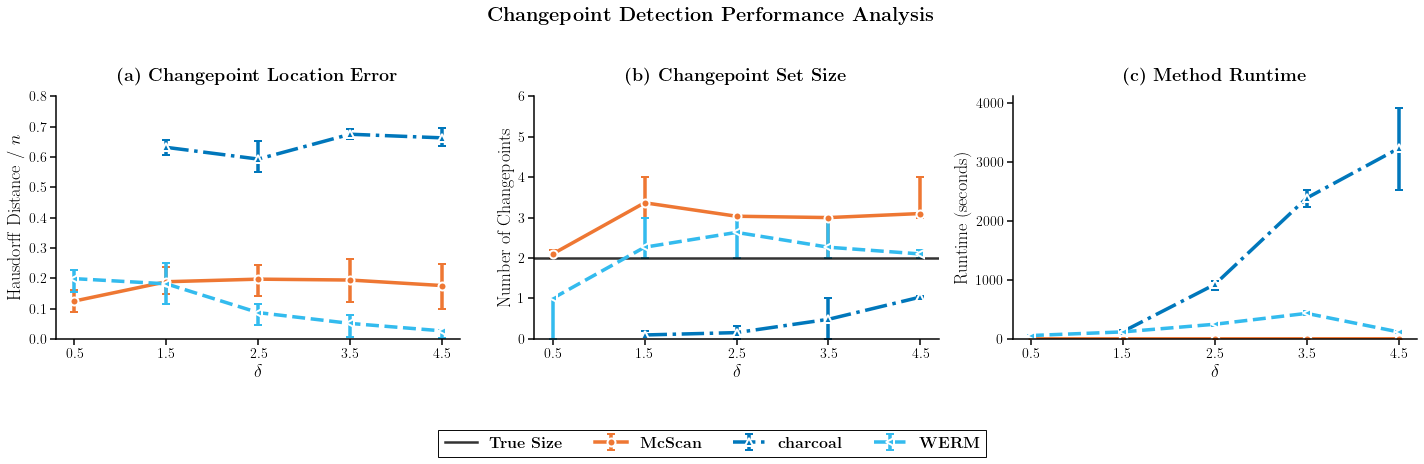

2. Confidence bands (publication style)...


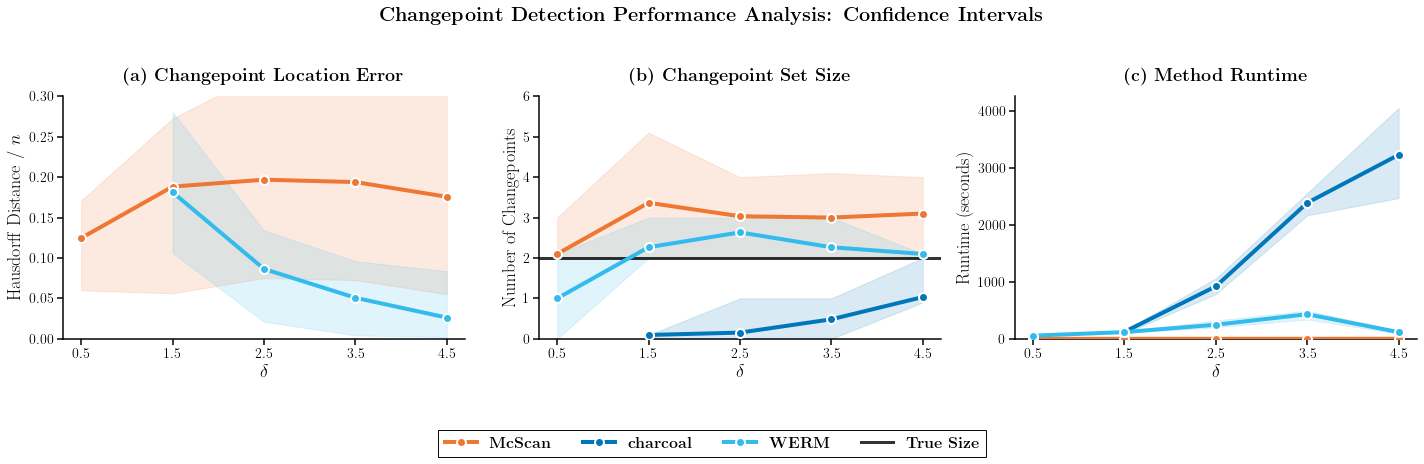

3. Box plots (publication style)...
17:39:17 - No valid data for charcoal for delta 0.5 (haus). Skipping box plot for this point.
17:39:17 - No valid data for charcoal for delta 0.5 (size). Skipping box plot for this point.
17:39:17 - No valid data for charcoal for delta 0.5 (runtime). Skipping box plot for this point.


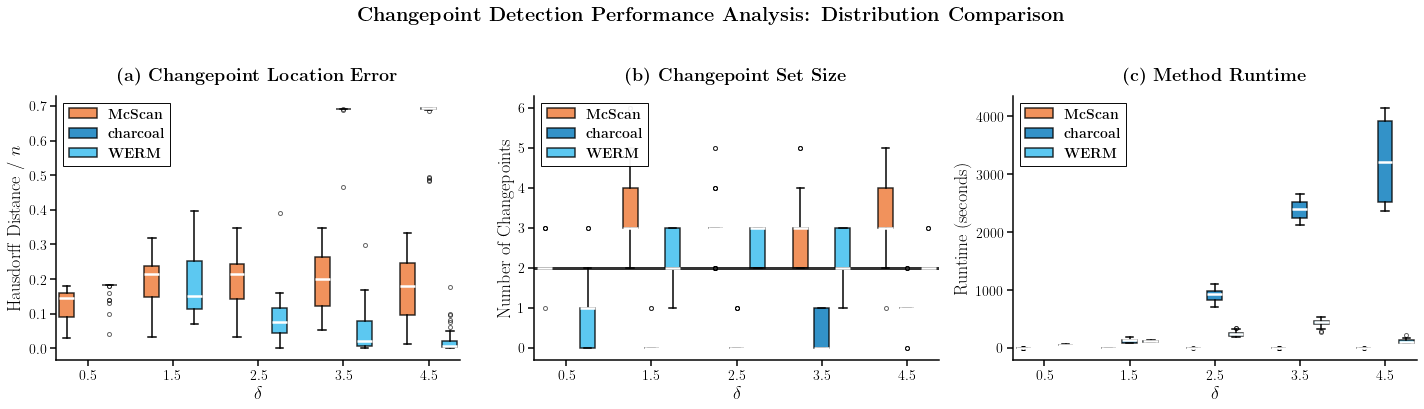

4. Enhanced changepoint histograms (publication style)...


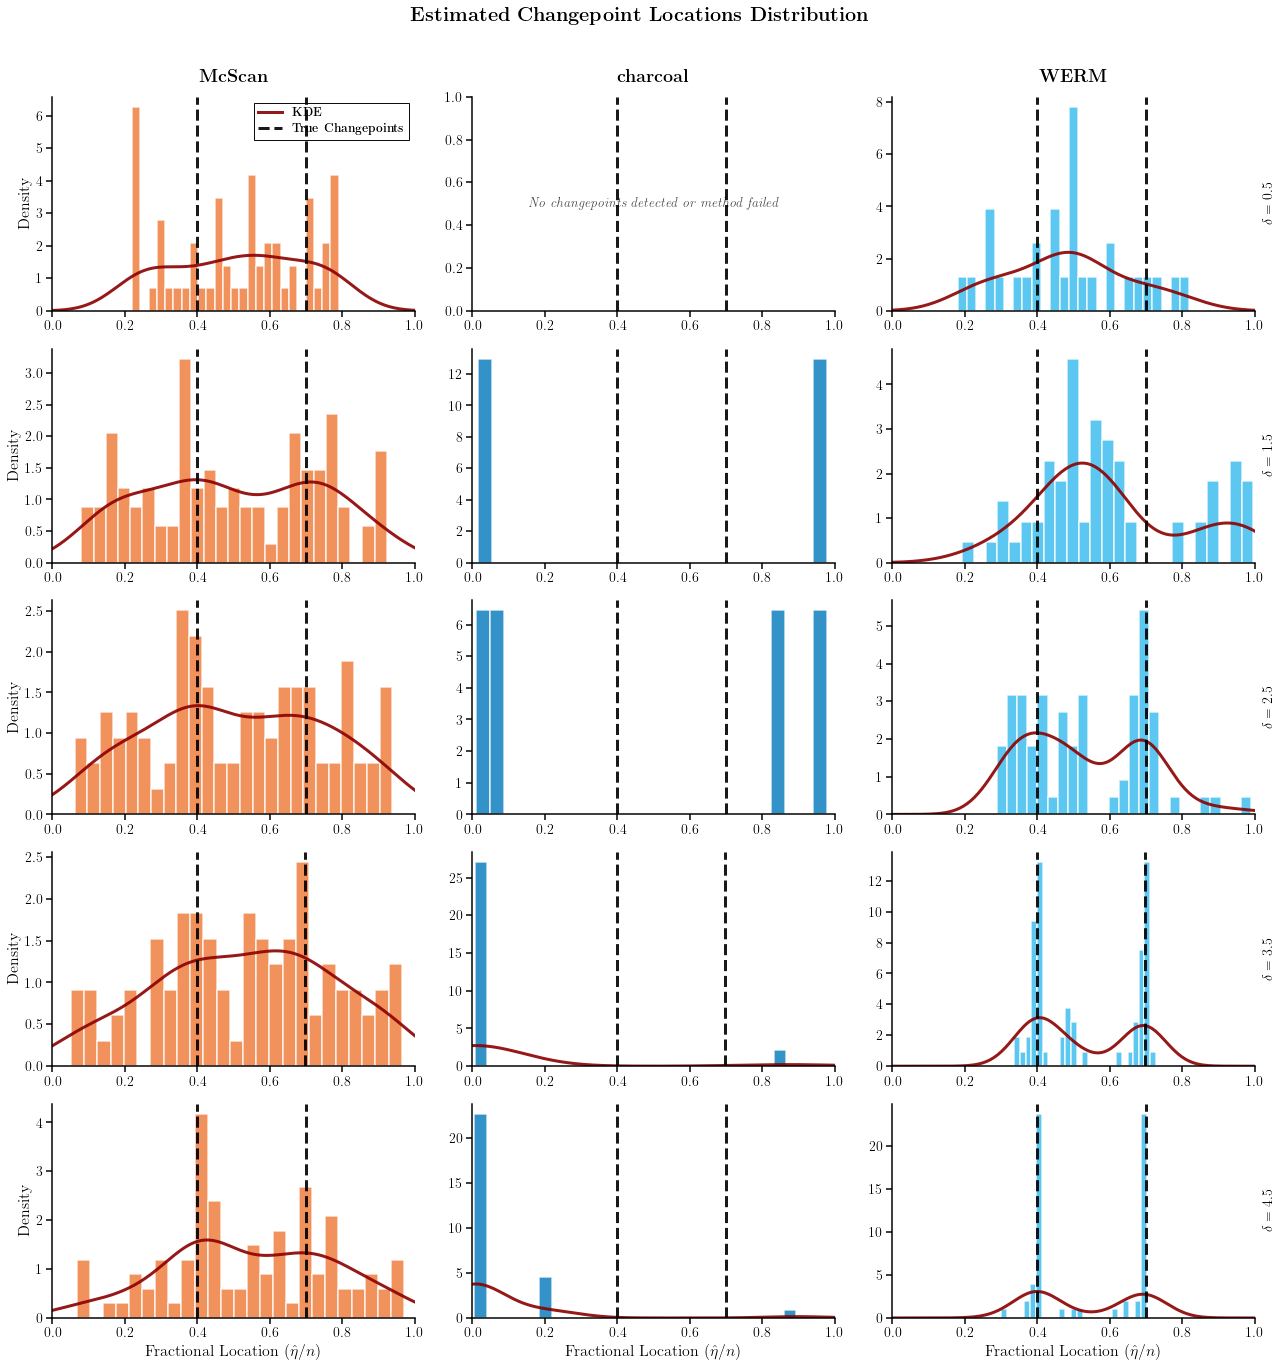

17:39:19 - Publication-ready plotting completed in 2.33 seconds


In [18]:
# --- Publication-Ready Enhanced Plotting Results ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,
    'axes.linewidth': 1.5,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'legend.frameon': True,
    'legend.fancybox': False,
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 3.0,
    'lines.markersize': 8,
    'figure.dpi': 72,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

main_logger.info("Creating publication-ready plots...")
plotting_start_time = time.time()

# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB', '#FF8800', '#DDAA33', '#BBCC33'] # Expanded palette for more methods
PAL = TOL_VIBRANT

# Ensure colors are assigned from the palette in order
for i, method_obj in enumerate(methods_to_evaluate):
    method_obj['color'] = PAL[i % len(PAL)] # Cycle through colors if more methods than palette entries

print(f"Using palette: {[m['color'] for m in methods_to_evaluate]} (Paul Tol Vibrant assigned to methods)")

def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

# --- Option 1: Publication-Ready Asymmetric Error Bars ---
def plot_with_asymmetric_errors_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis}', fontsize=20, y=0.98)

    # Prepare plotting parameters from methods_to_evaluate
    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]
    plot_markers = [method['marker'] for method in methods_to_evaluate]
    plot_linestyles = [method['linestyle'] for method in methods_to_evaluate]

    # Hausdorff Distance Plot
    ax = axs[0]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'haus_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Hausdorff). Skipping plot for this metric.")
            continue
        # Set all infs to NaN for plotting
        data = np.where(np.isinf(data), np.nan, data)
        # Calculate means and asymmetric errors
        # Using np.nanmean to ignore NaNs in the calculation
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim((0, 0.8))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Hausdorff Distance / $n$', fontsize=18)
    ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Changepoint Set Size Plot
    ax = axs[1]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'size_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Size). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
    ax.set_ylim((0, L + 2))
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Number of Changepoints', fontsize=18)
    ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    # Runtime Plot
    ax = axs[2]
    for i, method_obj in enumerate(methods_to_evaluate):
        method_name = method_obj['name']
        data = results[f'runtime_{method_name}']
        if np.all(np.isnan(data)):
            main_logger.warning(f"No successful trials for {method_name} (Runtime). Skipping plot for this metric.")
            continue
        means = np.nanmean(data, axis=1)
        errors = get_asymmetric_errors(data)
        ax.errorbar(delta_list, means, yerr=errors, # Changed x-axis to delta_list
                    label=plot_labels[i], marker=plot_markers[i], ls=plot_linestyles[i],
                    color=plot_colors[i], capsize=4, capthick=2, markersize=8,
                    linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
    ax.set_ylabel(r'Runtime (seconds)', fontsize=18)
    ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
    ax.set_xticks(delta_list) # Changed x-ticks
    ax.tick_params(axis='both', which='major', width=1.5, length=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    fig.savefig('figures/scratch_M2.png', dpi=72, bbox_inches='tight')
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 2: Publication-Ready Confidence Bands ---
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Confidence Intervals}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]

    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        for method_idx, method_obj in enumerate(methods_to_evaluate):
            method_name = method_obj['name']
            data = results[f'{metric}_{method_name}']
            if np.all(np.isnan(data)):
                main_logger.warning(f"No successful trials for {method_name} ({metric}). Skipping plot for this metric.")
                continue
            means = np.nanmean(data, axis=1)
            p10 = np.nanpercentile(data, 10, axis=1)
            p90 = np.nanpercentile(data, 90, axis=1)
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)

            ax.fill_between(delta_list, p10, p90, color=plot_colors[method_idx], # Changed x-axis to delta_list
                            alpha=0.15, zorder=1)
            ax.plot(delta_list, means, color=plot_colors[method_idx], linewidth=4, # Changed x-axis to delta_list
                    marker='o', markersize=9, label=plot_labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)

        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        ax.set_xticks(delta_list) # Changed x-ticks
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)

    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                ncol=len(methods_to_evaluate)+1, fontsize=16, frameon=True,
                edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# --- Option 3: Publication-Ready Box Plots ---
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Changepoint Detection Performance Analysis: Distribution Comparison}',
                    fontsize=20, y=0.98)

    plot_labels = [method['label'] for method in methods_to_evaluate]
    plot_colors = [method['color'] for method in methods_to_evaluate]

    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]

    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        spacing = len(methods_to_evaluate) + 1
        for delta_idx, delta_val in enumerate(delta_list): # Iterating over delta_list
            box_data = []
            box_positions = []
            box_colors = []
            for method_idx, method_obj in enumerate(methods_to_evaluate):
                method_name = method_obj['name']
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                valid_data = data[~np.isnan(data)]
                if len(valid_data) > 0:
                    box_data.append(valid_data)
                    box_positions.append(delta_idx * spacing + method_idx)
                    box_colors.append(plot_colors[method_idx])
                else:
                    main_logger.warning(f"No valid data for {method_name} for delta {delta_val:.1f} ({metric}). Skipping box plot for this point.")

            if len(box_data) > 0:
                bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                                 patch_artist=True, showfliers=True,
                                 flierprops=dict(marker='o', markersize=4, alpha=0.6),
                                 medianprops=dict(color='white', linewidth=2.5),
                                 boxprops=dict(linewidth=1.5),
                                 whiskerprops=dict(linewidth=1.5),
                                 capprops=dict(linewidth=1.5))
                for patch, color in zip(bp['boxes'], box_colors):
                    patch.set_facecolor(color)
                    patch.set_alpha(0.8)
                    patch.set_edgecolor('black')

        delta_positions = [i * spacing + (len(methods_to_evaluate) - 1) / 2 for i in range(len(delta_list))]
        ax.set_xticks(delta_positions) # Changed x-ticks to delta_positions
        ax.set_xticklabels([f'{d:.1f}' for d in delta_list]) # Changed x-tick labels
        ax.set_xlabel(r'$\delta$', fontsize=18) # Changed x-label
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)

        legend_elements = [plt.Rectangle((0,0),1,1, facecolor=plot_colors[i],
                                         alpha=0.8, edgecolor='black',
                                         linewidth=1.5, label=plot_labels[i])
                                         for i in range(len(methods_to_evaluate))]
        ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                   frameon=True, edgecolor='black', framealpha=0.95)

        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                         linewidth=3, alpha=0.8, label=r'\textbf{True Size}')

        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Publication-Ready Changepoint Histograms ---
def plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, methods_to_plot_names):
    """
    Publication-ready changepoint location histograms
    """
    # Map method names to their plotting properties
    method_plotting_info = {m['name']: {'label': m['label'], 'color': m['color']} for m in methods_to_evaluate}

    selected_delta_idx = list(range(len(delta_list)))
    selected_deltas = delta_list
    # Adjust figsize to accommodate more columns
    fig, axes = plt.subplots(len(selected_deltas), len(methods_to_plot_names),
                             figsize=(6 * len(methods_to_plot_names), 4 * len(selected_deltas)))

    # Ensure axes is always a 2D array, even for single row/column plots
    if len(selected_deltas) == 1 and len(methods_to_plot_names) == 1:
        axes = np.array([[axes]])
    elif len(methods_to_plot_names) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)

    fig.patch.set_facecolor('white')
    fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
                     fontsize=20, y=0.98)

    # Use the fixed_noise_scale defined globally
    global fixed_noise_scale # Access the global fixed_noise_scale

    for row, (delta_idx, delta_val) in enumerate(zip(selected_delta_idx, selected_deltas)):
        n = int(delta_val * p) # n depends on delta, which is now the varying parameter
        for col, method_name in enumerate(methods_to_plot_names):
            ax = axes[row, col]
            ax.set_facecolor('white')

            all_chgpts = []
            for stored_delta_idx, chgpts_data in results[f'chgpts_{method_name}']:
                if stored_delta_idx == delta_idx:
                    if chgpts_data is not None and len(chgpts_data) > 0 and not (np.isscalar(chgpts_data) and np.isnan(chgpts_data)):
                        chgpts_array = np.array(chgpts_data)
                        valid_chgpts = chgpts_array[chgpts_array != -1]
                        for chgpt in valid_chgpts:
                            fractional_chgpt = chgpt / n
                            all_chgpts.append(fractional_chgpt)

            if len(all_chgpts) > 0:
                ax.hist(all_chgpts, bins=25, alpha=0.8,
                         color=method_plotting_info[method_name]['color'],
                         density=True, edgecolor='white', linewidth=1.5)
                if len(all_chgpts) > 8:
                    from scipy.stats import gaussian_kde
                    kde = gaussian_kde(all_chgpts)
                    x_range = np.linspace(0, 1, 200)
                    kde_values = kde(x_range)
                    ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                             alpha=0.9, label=r'\textbf{KDE}')
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected or method failed}',
                         transform=ax.transAxes, ha='center', va='center',
                         fontsize=14, alpha=0.7, style='italic')

            current_true_chgpts = None
            for stored_delta_idx, true_chgpts_data in results['true_chgpts']:
                if stored_delta_idx == delta_idx:
                    current_true_chgpts = true_chgpts_data
                    break
            if current_true_chgpts is not None:
                for i_true, true_chgpt in enumerate(current_true_chgpts):
                    fractional_true_chgpt = true_chgpt / n
                    ax.axvline(x=fractional_true_chgpt, color='black', linestyle='--', linewidth=3,
                                 alpha=0.9, zorder=10,
                                 label=r'\textbf{True Changepoints}' if i_true == 0 else "")
            ax.set_xlim(0, 1)

            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)

            if row == 0:
                ax.set_title(f'{method_plotting_info[method_name]["label"]}', fontsize=18, pad=15)

            if col == len(methods_to_plot_names)-1:
                ax.text(1.02, 0.5, f'$\delta = {delta_val}$', transform=ax.transAxes, # Changed to delta
                                 rotation=90, verticalalignment='center', fontsize=14,
                                 fontweight='bold')

            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)

            if row == 0 and col == 0 and (len(all_chgpts) > 0 or current_true_chgpts is not None):
                handles, labels = ax.get_legend_handles_labels()
                unique_labels = {}
                for handle, label in zip(handles, labels):
                    if label not in unique_labels:
                        unique_labels[label] = handle
                ax.legend(unique_labels.values(), unique_labels.keys(), loc='upper right', fontsize=12, frameon=True,
                                         edgecolor='black', framealpha=0.95)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.show()

# Execute publication-ready plotting options
print("Creating publication-ready plots...")
print("1. Asymmetric error bars (publication style)...")
plot_with_asymmetric_errors_publication()
print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()
print("3. Box plots (publication style)...")
plot_with_boxplots_publication()
print("4. Enhanced changepoint histograms (publication style)...")
plot_changepoint_histograms_publication(results, delta_list, fractional_chgpt_locations, method_names_list)
plotting_time = time.time() - plotting_start_time
main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# Save results to a file
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Updated filename to reflect fixed noise_scale and varying delta
filename = f"results/M2_varydelta_{method_names_for_filename}_results_p{p}_L{L}_delta{''.join(map(str, map(int, delta_list)))}_noisecale{fixed_noise_scale:.3f}_seed{random_seed}.pkl"
with open(filename, 'wb') as f:
    pickle.dump({
        'results': results,
        'params': {
            'p': p,
            'L': L,
            'delta_list': delta_list, # Updated to delta_list
            'fixed_noise_scale': fixed_noise_scale, # Stored fixed_noise_scale
            'num_trials': num_trials,
            'fractional_chgpt_locations': fractional_chgpt_locations,
            'n_jobs': n_jobs,
            'successful_trials_counts': results['successful_trials'],
            'methods_evaluated': methods_to_evaluate,
            'random_seed': random_seed
        }
    }, f)

# Load data, plot, and save. 

<>:247: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:253: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:253: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:247: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:253: SyntaxWarning: "is not" with a literal. Did you mean "!="?
<>:253: SyntaxWarning: "is not" with a literal. Did you mean "!="?


Removing 110 matplotlib modules...
Successfully set backend to: pgf
main_logger not defined, skipping logging.
Using palette: ['#EE7733', '#0077BB', '#33BBEE', '#EE3377'] (Paul Tol Vibrant)
Creating publication-ready plots...
1. Asymmetric error bars (publication style)...
labels b4:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']
labels after:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']
data for McScan before inf handling:  [[0.15       0.17       0.15       0.16       0.15       0.1
  0.06       0.18       0.03       0.1        0.11       0.13
  0.14       0.16       0.06       0.09       0.18       0.09
  0.16       0.11       0.06       0.17       0.17       0.16
  0.07       0.16       0.18       0.09       0.05       0.15      ]
 [0.22333333 0.24       0.22666667 0.31333333 0.03333333 0.05666667
  0.27       0.21333333 0.26666667 0.16333333 0.06333333 0.05333333
  0.14666667 0.15       0.21333333 0.21666667 0.22333333 0.26333333
  0.22333333 0.1166

/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:247: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location':
/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:253: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location' and plot_type is not 'size':
/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:253: SyntaxWarning: "is not" with a literal. Did you mean "!="?
  if plot_type is not 'location' and plot_type is not 'size':
/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:165: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:127: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: Al

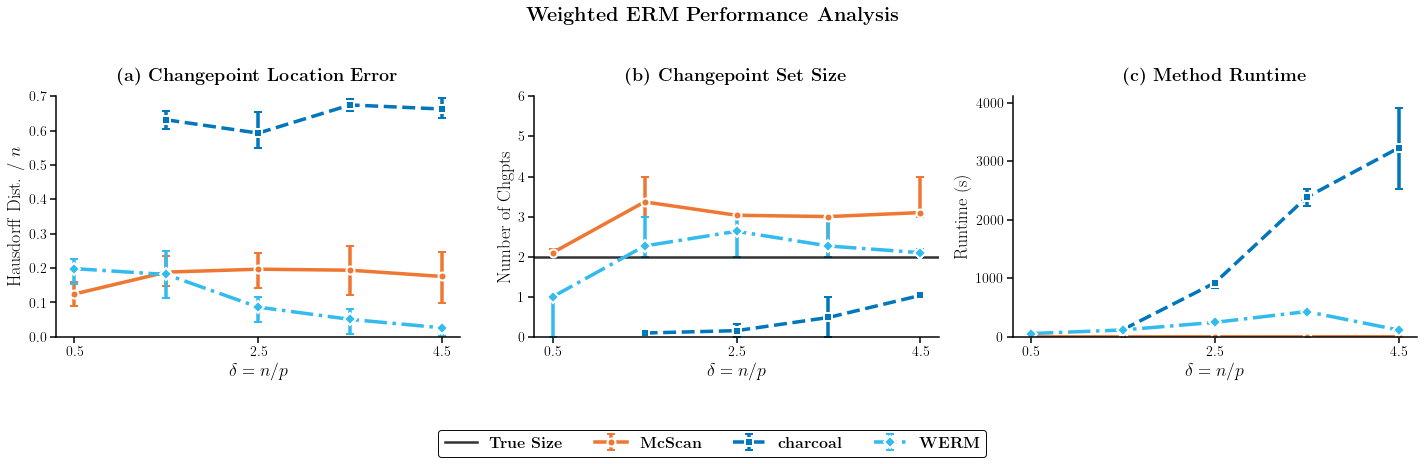

1. Asymmetric error bars (publication style) - location
labels b4:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']
labels after:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']
data for McScan before inf handling:  [[0.15       0.17       0.15       0.16       0.15       0.1
  0.06       0.18       0.03       0.1        0.11       0.13
  0.14       0.16       0.06       0.09       0.18       0.09
  0.16       0.11       0.06       0.17       0.17       0.16
  0.07       0.16       0.18       0.09       0.05       0.15      ]
 [0.22333333 0.24       0.22666667 0.31333333 0.03333333 0.05666667
  0.27       0.21333333 0.26666667 0.16333333 0.06333333 0.05333333
  0.14666667 0.15       0.21333333 0.21666667 0.22333333 0.26333333
  0.22333333 0.11666667 0.16       0.29666667 0.13333333 0.25666667
  0.32       0.22333333 0.16666667 0.22666667 0.03333333 0.15666667]
 [0.164      0.15       0.076      0.246      0.16       0.334
  0.234      0.04       0.338      0.

/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:165: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:127: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


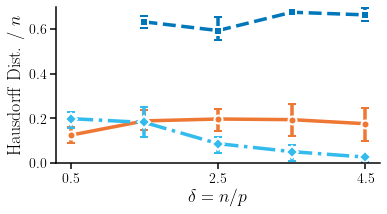

1. Asymmetric error bars (publication style) - size
labels b4:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']
labels after:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']


/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:194: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:127: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)
/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


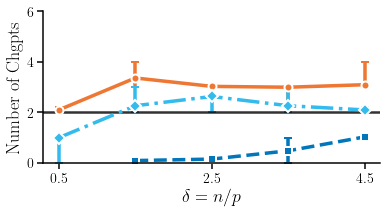

1. Asymmetric error bars (publication style) - runtime
labels b4:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']
labels after:  ['\\textbf{McScan}', '\\textbf{charcoal}', '\\textbf{WERM}']


/var/folders/kh/5q2qjwdd4sz5cvjt10c51cgh0000gn/T/ipykernel_1959/613888525.py:223: RuntimeWarning: Mean of empty slice
  means = np.nanmean(data, axis=1)


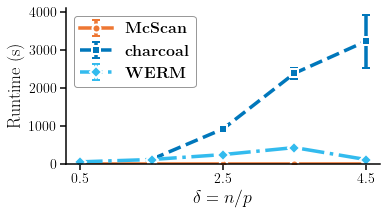

2. Confidence bands (publication style)...


/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


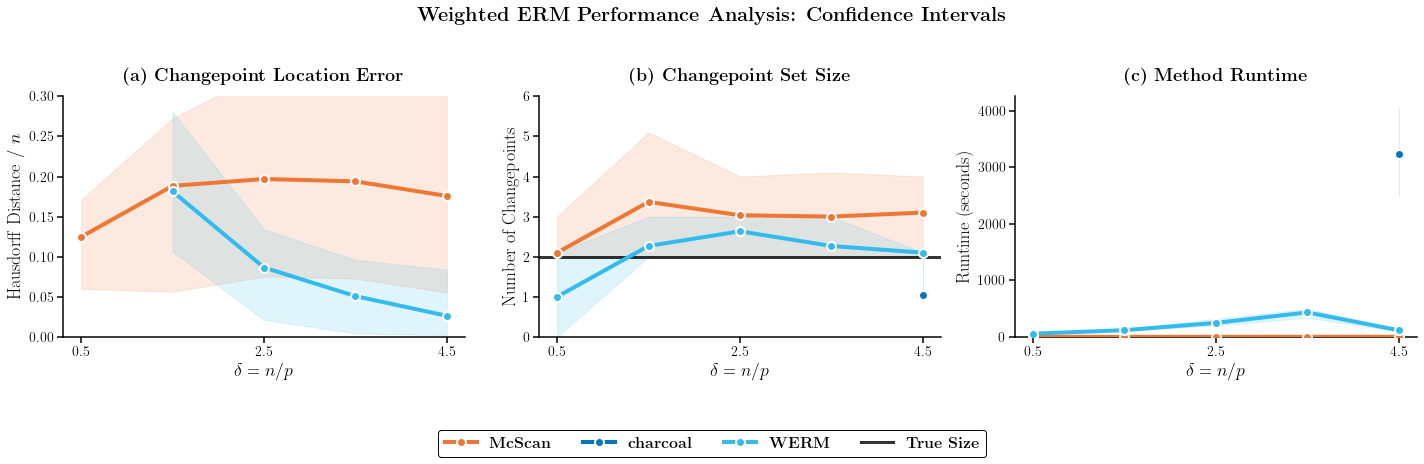

3. Box plots (publication style)...


/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/Users/gabrielarpino/.local/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


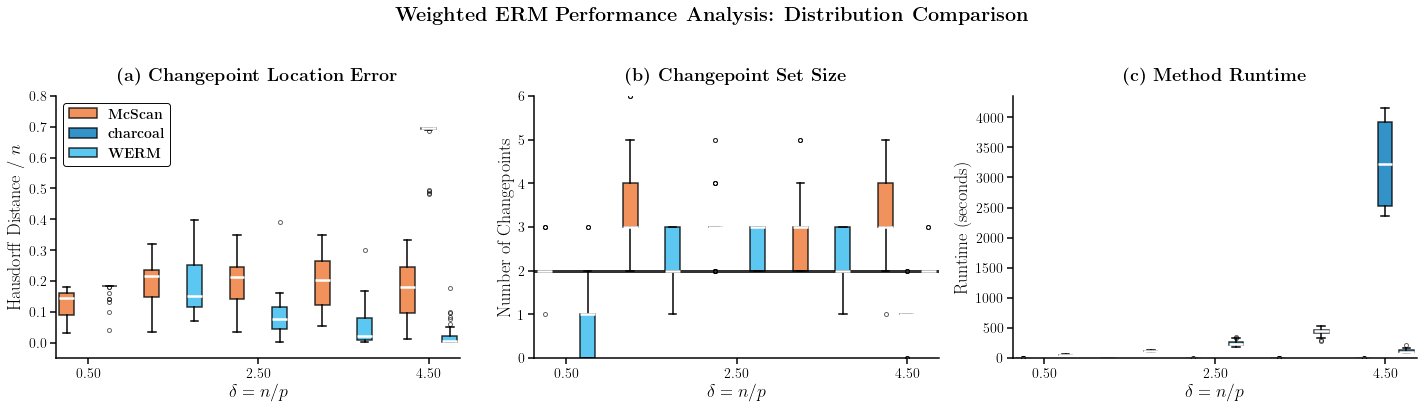

4. Enhanced changepoint histograms (publication style)...
Publication-ready plotting completed in 2.88 seconds


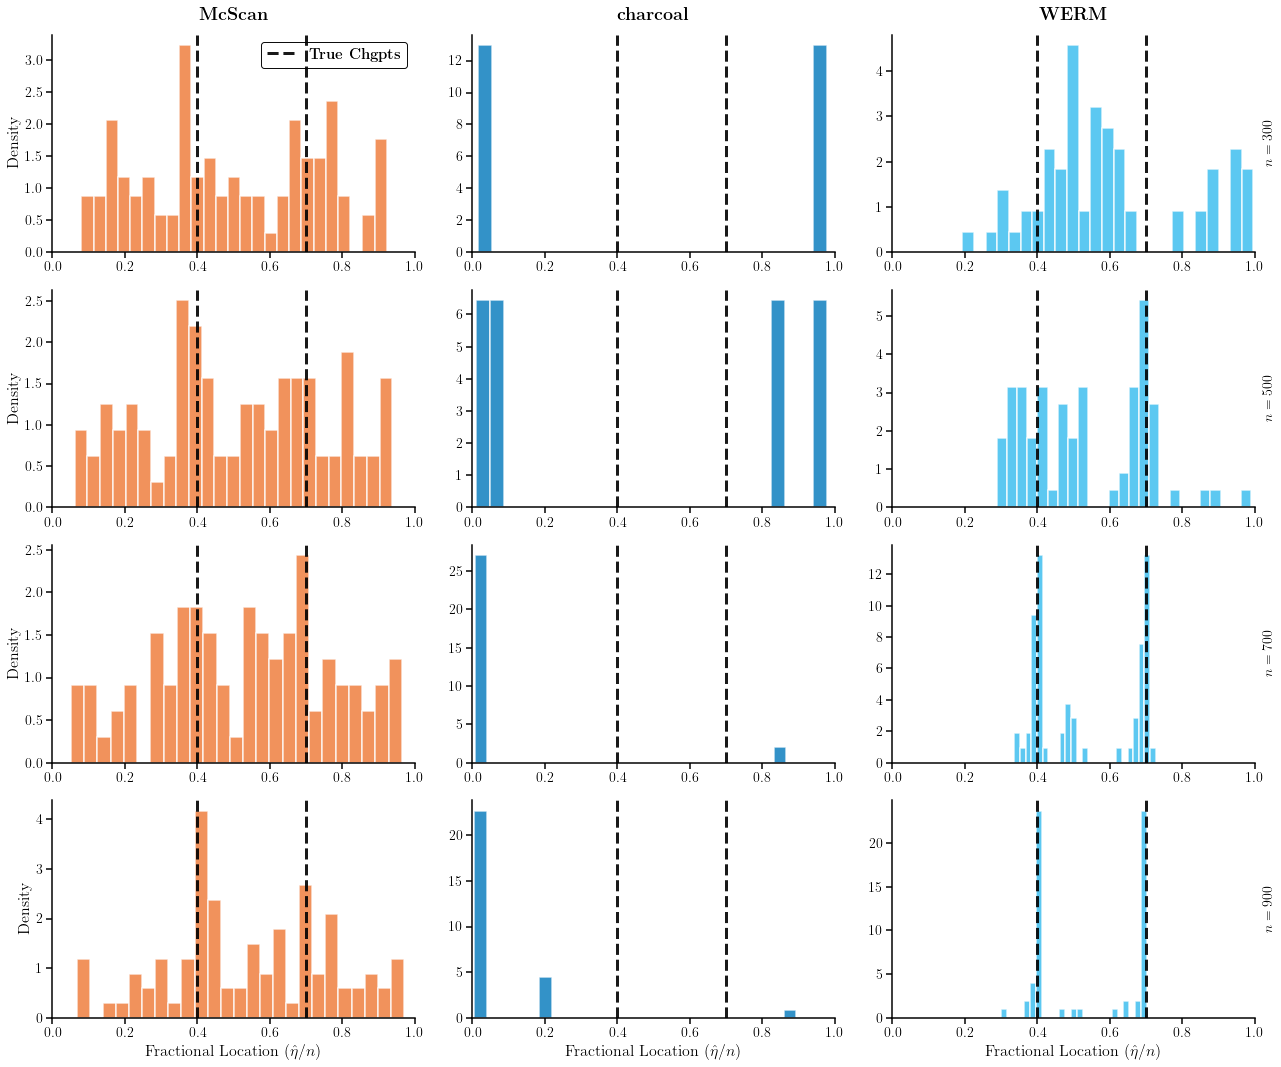

In [2]:
# -----------------------------------------------------------------------------
# 5. Publication-Ready Enhanced Plotting Results
# -----------------------------------------------------------------------------
import sys
import numpy as np # Make sure numpy is imported
import time # Make sure time is imported
import matplotlib # Make sure matplotlib is imported
import gc
from scipy.stats import gaussian_kde # For KDE in histograms
import matplotlib.pyplot as plt
import pickle


# Close all existing figures first
try:
    import matplotlib.pyplot as plt
    plt.close('all')
except:
    pass

# Remove ALL matplotlib-related modules more thoroughly
modules_to_remove = []
for module_name in list(sys.modules.keys()):
    if any(module_name.startswith(prefix) for prefix in ['matplotlib', 'mpl_toolkits']):
        modules_to_remove.append(module_name)

print(f"Removing {len(modules_to_remove)} matplotlib modules...")
for module_name in modules_to_remove:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Clear any cached references
gc.collect()

# Now import fresh matplotlib
matplotlib.use('pgf')
import matplotlib.pyplot as plt

print(f"Successfully set backend to: {matplotlib.get_backend()}")

# Set publication-ready matplotlib parameters
plt.rcParams.update({
    'pgf.texsystem': 'pdflatex',  # or 'xelatex', 'lualatex'
    'pgf.preamble': r'''
        \usepackage{amsmath}
        \usepackage{amsfonts}
        \usepackage{amssymb}
        \usepackage{siunitx}
    ''',
    'font.size': 14,      # Base font size
    'font.family': 'serif',    # Use serif fonts
    'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'text.usetex': True,      # Enable LaTeX rendering
    'axes.linewidth': 1.5,    # Thicker axes
    'axes.labelsize': 16,     # Larger axis labels
    'axes.titlesize': 18,     # Larger titles
    'xtick.labelsize': 14,    # Larger tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 14,    # Larger legend
    'legend.frameon': True,    # Legend frame
    'legend.fancybox': True,  # Clean rectangle
    'legend.edgecolor': 'black',
    'legend.framealpha': 0.95,
    'lines.linewidth': 4.0,    # Thicker lines by default
    'lines.markersize': 8,     # Larger markers
    'figure.dpi': 72,          # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

# Assuming `main_logger` is defined elsewhere in your script or you can remove this line
try:
    main_logger.info("Creating publication-ready plots...")
except NameError:
    print("main_logger not defined, skipping logging.")

plotting_start_time = time.time()

# RECOMMENDED: Most aesthetic AND colorblind-friendly palette
# Paul Tol "Vibrant" - optimal balance of aesthetics and accessibility
TOL_VIBRANT = ['#EE7733', '#0077BB', '#33BBEE', '#EE3377',
               '#CC3311', '#009988', '#BBBBBB']

# Use the most aesthetic palette
PAL = TOL_VIBRANT
# random.shuffle(PAL)

print(f"Using palette: {PAL[:4]} (Paul Tol Vibrant)")

# --- Load data and set up global parameters (moved from end to top for clarity) ---
# This part assumes you have a filename to load from, or you'll need to define
# `results`, `params`, `p`, `L`, `noise_std`, `δ_list`, `fractional_chgpt_locations`,
# `n_jobs`, `methods_to_evaluate`, `random_seed` directly or load them differently.

# Example of how to load the data (adjust filename as needed)
# You need to ensure the `results` dictionary and `params` are populated
# before calling the plotting functions.

# This filename needs to match your saved results
# For the example, I'll use the one provided in the original code.
# Replace with your actual filename if different.
_example_filename = 'results/M2_varydelta_McScan_charcoal_WERM-unp_results_p200_L4_delta01234_noisecale0.316_seed42.pkl'
with open(_example_filename, 'rb') as f:
    data = pickle.load(f)
results = data['results']
params = data['params']
p = params['p']
L = params['L']
noise_std = params['fixed_noise_scale']  # Assuming this is the fixed noise scale
δ_list = params['delta_list']
fractional_chgpt_locations = params['fractional_chgpt_locations']
n_jobs = params['n_jobs']
methods_to_evaluate = params['methods_evaluated']
random_seed = params.get('random_seed', None)

# Extract method names for plotting
method_names_list = [method['name'] for method in methods_to_evaluate]

# -----------------------------------------------------------------------------
# Option 1: Publication-Ready Asymmetric Error Bars
# -----------------------------------------------------------------------------

# Calculate percentiles for asymmetric error bars
def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

def plot_with_asymmetric_errors_publication(plot_type='all'):
    """ plot_type is either: 'all', 'location', 'size', 'runtime'. """
    if plot_type == 'all':
        fig, axs = plt.subplots(1, 3, figsize=(20, 6))
        fig.suptitle(r'\textbf{Weighted ERM Performance Analysis}', fontsize=20, y=0.98)
    else:
        fig, axs = plt.subplots(1, 1, figsize=(5.6, 3.2))
    
    # Use method_names_list from the loaded/generated params
    methods = method_names_list
    colors = PAL[:len(methods)] # Use as many colors as methods
    
    # Define markers and linestyles to match the number of methods
    markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', '*']
    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 1))]
    
    labels = [method['label'] for method in methods_to_evaluate] # Use labels from methods_to_evaluate
    print("labels b4: ", labels)
    # labels = ['\\textbf{McScan}', '\\textbf{MOSEG}', '\\textbf{WERM}']
    # labels = ['McScan', 'MOSEG', 'WERM']
    print("labels after: ", labels)
    
    # Hausdorff Distance Plot
    if plot_type == 'all' or plot_type == 'location':
        if plot_type == 'all': ax = axs[0]
        elif plot_type == 'location': ax = axs
        for i, method_name in enumerate(methods):
            data = results[f'haus_{method_name}']
            # Set all infs to NaN for plotting
            print(f"data for {method_name} before inf handling: ", data)
            data = np.where(np.isinf(data), np.nan, data)
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        ax.set_ylim((0, 0.7))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Hausdorff Dist. / $n$', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(a) Changepoint Location Error}', fontsize=18, pad=15)
        
        # Cleaner x-axis with fewer ticks
        ax.set_xticks(δ_list[::2])  # Show every other tick
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Changepoint Set Size Plot
    if plot_type == 'all' or plot_type == 'size':
        if plot_type == 'all': ax = axs[1]
        elif plot_type == 'size': ax = axs

        for i, method_name in enumerate(methods):
            data = results[f'size_{method_name}']
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                   linewidth=2.5, alpha=0.8, label=r'\textbf{True Size}')
        ax.set_ylim((0, L + 2))
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Number of Chgpts', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(b) Changepoint Set Size}', fontsize=18, pad=15)
        
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Runtime Plot
    if plot_type == 'all' or plot_type == 'runtime':
        if plot_type == 'all': ax = axs[2]
        elif plot_type == 'runtime': ax = axs
        for i, method_name in enumerate(methods):
            data = results[f'runtime_{method_name}']
            means = np.nanmean(data, axis=1)
            errors = get_asymmetric_errors(data)
            
            ax.errorbar(δ_list, means, yerr=errors,
                        label=labels[i], marker=markers[i % len(markers)], ls=linestyles[i % len(linestyles)],
                        color=colors[i], capsize=4, capthick=2, markersize=8,
                        linewidth=3.5, markeredgewidth=2, markeredgecolor='white')
        
        ax.set_ylim(bottom=0)
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(r'Runtime (s)', fontsize=18)
        if plot_type == 'all':
            ax.set_title(r'\textbf{(c) Method Runtime}', fontsize=18, pad=15)
        
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    if plot_type == 'all':
        # Single legend for all subplots
        handles, labels_leg = axs[1].get_legend_handles_labels()
        if plot_type is not 'location':
            fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                    ncol=len(methods)+1, fontsize=16, frameon=True,
                    edgecolor='black', framealpha=0.95)
        plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    else:
        if plot_type is not 'location' and plot_type is not 'size':
            ax.legend(loc='best', prop={'size': 16}, fancybox = True, framealpha = 0.4)
        fig.tight_layout()
    
    # plt.show() # Removed plt.show() as per the original structure that saves then shows
    return fig, axs

# -----------------------------------------------------------------------------
# Option 2: Publication-Ready Confidence Bands
# -----------------------------------------------------------------------------
def plot_with_confidence_bands_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Confidence Intervals}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}', (0, 0.3)),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}', (0, L + 2)),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}', None)]
    
    for ax_idx, (metric, ylabel, title, ylim) in enumerate(metrics):
        ax = axs[ax_idx]
        
        for method_idx, method_name in enumerate(methods):
            data = results[f'{metric}_{method_name}']
            means = np.mean(data, axis=1)
            
            # Calculate confidence intervals (10th and 90th percentiles)
            p10 = np.percentile(data, 10, axis=1)
            p90 = np.percentile(data, 90, axis=1)
            
            p10 = np.minimum(p10, means)
            p90 = np.maximum(p90, means)
            
            # Plot confidence band first (so it's behind the line)
            ax.fill_between(δ_list, p10, p90, color=colors[method_idx],
                            alpha=0.15, zorder=1)
            
            # Plot mean line with markers
            ax.plot(δ_list, means, color=colors[method_idx], linewidth=4,
                    marker='o', markersize=9, label=labels[method_idx], zorder=3,
                    markeredgewidth=2, markeredgecolor='white')
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}', zorder=2)
        
        if ylim:
            ax.set_ylim(ylim)
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)
        
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Cleaner axes
        ax.set_xticks(δ_list[::2])
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    # Single legend for all subplots
    handles, labels_leg = axs[1].get_legend_handles_labels()
    fig.legend(handles, labels_leg, loc='upper center', bbox_to_anchor=(0.5, 0.02),
               ncol=len(methods)+1, fontsize=16, frameon=True,
               edgecolor='black', framealpha=0.95)
    
    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Option 3: Publication-Ready Box Plots
# -----------------------------------------------------------------------------
def plot_with_boxplots_publication():
    fig, axs = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle(r'\textbf{Weighted ERM Performance Analysis: Distribution Comparison}',
                 fontsize=20, y=0.98)
    
    methods = method_names_list
    colors = PAL[:len(methods)]
    labels = [method['label'] for method in methods_to_evaluate]
    
    metrics = [('haus', r'Hausdorff Distance / $n$', r'\textbf{(a) Changepoint Location Error}'),
               ('size', r'Number of Changepoints', r'\textbf{(b) Changepoint Set Size}'),
               ('runtime', r'Runtime (seconds)', r'\textbf{(c) Method Runtime}')]
    
    for ax_idx, (metric, ylabel, title) in enumerate(metrics):
        ax = axs[ax_idx]
        
        # Create box plots for each delta value
        for delta_idx, delta in enumerate(δ_list):
            box_data = []
            box_positions = []
            box_colors = []
            
            for method_idx, method_name in enumerate(methods):
                data = results[f'{metric}_{method_name}'][delta_idx, :]
                box_data.append(data)
                box_positions.append(delta_idx * (len(methods) + 1) + method_idx) # Adjusted spacing
                box_colors.append(colors[method_idx])
            
            # Create publication-ready box plots
            bp = ax.boxplot(box_data, positions=box_positions, widths=0.7,
                            patch_artist=True, showfliers=True,
                            flierprops=dict(marker='o', markersize=4, alpha=0.6),
                            medianprops=dict(color='white', linewidth=2.5),
                            boxprops=dict(linewidth=1.5),
                            whiskerprops=dict(linewidth=1.5),
                            capprops=dict(linewidth=1.5))
            
            # Color the boxes
            for patch, color in zip(bp['boxes'], box_colors):
                patch.set_facecolor(color)
                patch.set_alpha(0.8)
                patch.set_edgecolor('black')
        
        # Set x-axis labels - only show every other delta for cleanliness
        # Adjust delta_positions calculation
        delta_positions = [i * (len(methods) + 1) + (len(methods) - 1) / 2.0 for i in range(len(δ_list))]
        ax.set_xticks(delta_positions[::2])  # Every other position
        ax.set_xticklabels([f'{d:.2f}' for d in δ_list[::2]])
        ax.set_xlabel(r'$\delta = n/p$', fontsize=18)
        ax.set_ylabel(ylabel, fontsize=18)
        ax.set_title(title, fontsize=18, pad=15)
        
        # Add legend (only for first subplot)
        if ax_idx == 0:
            legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors[i],
                                             alpha=0.8, edgecolor='black',
                                             linewidth=1.5, label=labels[i])
                               for i in range(len(methods))]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=14,
                      frameon=True, edgecolor='black', framealpha=0.95)
        
        # Add true size line for size plot
        if metric == 'size':
            ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle='-',
                       linewidth=3, alpha=0.8, label=r'\textbf{True Size}')
        
        # Set y-limits for better visibility
        if metric == 'haus':
            ax.set_ylim((-0.05, 0.8))
        elif metric == 'size':
            ax.set_ylim((0, L + 2))
        elif metric == 'runtime':
            ax.set_ylim(bottom=0)
        
        # Clean axes
        ax.tick_params(axis='both', which='major', width=1.5, length=6)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_linewidth(1.5)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# -----------------------------------------------------------------------------
# Publication-Ready Changepoint Histograms
# -----------------------------------------------------------------------------
def plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=['ext']):
    """
    Publication-ready changepoint location histograms
    Updated to use method_names_list and method_labels from methods_to_evaluate.
    """
    
    # Create method_names and method_colors dictionaries dynamically from methods_to_evaluate
    method_names_map = {method['name']: method['label'] for method in methods_to_evaluate}
    method_colors_map = {method['name']: PAL[i % len(PAL)] for i, method in enumerate(methods_to_evaluate)}
    
    # Filter methods based on methods_to_plot_names
    current_methods = [method for method in methods_to_evaluate if method['name'] in methods_to_plot_names]
    current_method_names = [method['name'] for method in current_methods]

    selected_deltas_idx = list(range(len(δ_list)))[1::1]
    selected_deltas = δ_list[1::1]
    
    fig, axes = plt.subplots(len(selected_deltas), len(current_methods),
                             figsize=(6*len(current_methods), 4*len(selected_deltas)))
    
    # Handle subplot configurations
    if len(selected_deltas) == 1 and len(current_methods) == 1:
        axes = np.array([[axes]])
    elif len(current_methods) == 1:
        axes = axes.reshape(-1, 1)
    elif len(selected_deltas) == 1:
        axes = axes.reshape(1, -1)
    
    fig.patch.set_facecolor('white')
    # fig.suptitle(r'\textbf{Estimated Changepoint Locations Distribution}',
    #              fontsize=20, y=0.98)
    
    for row, (delta_idx, delta) in enumerate(zip(selected_deltas_idx, selected_deltas)):
        n = int(delta * p)
        
        for col, method_name in enumerate(current_method_names):
            ax = axes[row, col]
            ax.set_facecolor('white')
            
            # Collect changepoints for the current method and delta
            all_chgpts = []
            chgpts_data_for_method = results.get(f'chgpts_{method_name}', [])
            for res_delta_idx, chgpts_list in chgpts_data_for_method:
                if res_delta_idx == delta_idx:
                    # chgpts_list can be a list of arrays or just a list/array
                    for chgpts in chgpts_list:
                        if hasattr(chgpts, '__len__') and len(chgpts) > 0:
                            chgpts_array = np.array(chgpts)
                            valid_chgpts = chgpts_array[chgpts_array != -1]
                            for chgpt in valid_chgpts:
                                fractional_chgpt = chgpt / n
                                all_chgpts.append(fractional_chgpt)
                        elif np.isscalar(chgpts) and chgpts != -1:
                            fractional_chgpt = chgpts / n
                            all_chgpts.append(fractional_chgpt)
            
            # Create publication-ready histogram
            if len(all_chgpts) > 0:
                counts, bins, patches = ax.hist(all_chgpts, bins=25, alpha=0.8,
                                                color=method_colors_map[method_name],
                                                density=True, edgecolor='white',
                                                linewidth=1.5)
                
                # Add KDE overlay if we have enough points
                # if len(all_chgpts) > 8:
                #     kde = gaussian_kde(all_chgpts)
                #     x_range = np.linspace(0, 1, 200)
                #     kde_values = kde(x_range)
                #     ax.plot(x_range, kde_values, color='darkred', linewidth=3,
                #             alpha=0.9, label=r'\textbf{KDE}')
                
            else:
                ax.text(0.5, 0.5, r'\textit{No changepoints detected}',
                        transform=ax.transAxes, ha='center', va='center',
                        fontsize=14, alpha=0.7, style='italic')
            
            # True changepoints with thicker lines
            for i, true_chgpt in enumerate(fractional_chgpt_locations):
                ax.axvline(x=true_chgpt, color='black', linestyle='--', linewidth=3,
                           alpha=0.9, zorder=10,
                           label=r'\textbf{True Chgpts}' if i == 0 else "")
            
            ax.set_xlim(0, 1)
            
            # Only label bottom row and leftmost column
            if row == len(selected_deltas)-1:
                ax.set_xlabel(r'Fractional Location ($\hat{\mathbf{\eta}}/n$)', fontsize=16)
            if col == 0:
                ax.set_ylabel(r'Density', fontsize=16)
            
            # Method name as title for top row
            if row == 0:
                ax.set_title(f'{method_names_map[method_name]}', fontsize=18, pad=15)
            
            # Add n value annotation
            if col == len(current_methods)-1:
                ax.text(1.02, 0.5, f'$n = {n}$', transform=ax.transAxes,
                        rotation=90, verticalalignment='center', fontsize=14,
                        fontweight='bold')
            
            # Clean axes
            ax.tick_params(axis='both', which='major', width=1.5, length=6)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_linewidth(1.5)
            ax.spines['bottom'].set_linewidth(1.5)
            
            # Add legend for first subplot if there are changepoints
            if row == 0 and col == 0 and len(all_chgpts) > 0:
                legend = ax.legend(loc='upper right', fontsize=15, frameon=True,
                                   edgecolor='black', framealpha=0.95, fancybox=True)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    # plt.show()
    return fig, axes


# Execute publication-ready plotting options
print("Creating publication-ready plots...")

print("1. Asymmetric error bars (publication style)...")
# Save the 'all' plot separately if desired, then individual ones
fig_all, axs_all = plot_with_asymmetric_errors_publication(plot_type='all')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_all.savefig(f'figures/SWERMvsEWERM_all_metrics_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
                #  dpi=300, bbox_inches='tight')
plt.show(fig_all) # Explicitly show the figure

print("1. Asymmetric error bars (publication style) - location")
fig_loc, axs_loc = plot_with_asymmetric_errors_publication(plot_type='location')
# fig_loc.savefig(f'figures/_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
method_names_for_filename = '_'.join(method['name'] for method in methods_to_evaluate)
# Save figure with the method names and parameters in the filename
fig_loc.savefig(f'figures/M2_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_loc.savefig(f'figures/M2_{method_names_for_filename}_location_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
             dpi=300, bbox_inches='tight')
plt.show(fig_loc)

print("1. Asymmetric error bars (publication style) - size")
fig_size, axs_size = plot_with_asymmetric_errors_publication(plot_type='size')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_size.savefig(f'figures/SWERMvsEWERM_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#              dpi=300, bbox_inches='tight')
fig_size.savefig(f'figures/M2_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_size.savefig(f'figures/M2_{method_names_for_filename}_size_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
             dpi=300, bbox_inches='tight')
plt.show(fig_size)


print("1. Asymmetric error bars (publication style) - runtime")
fig_rt, axs_rt = plot_with_asymmetric_errors_publication(plot_type='runtime')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.png', dpi=300, bbox_inches='tight')
# fig_rt.savefig(f'figures/SWERMvsEWERM_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
#                 dpi=300, bbox_inches='tight')
fig_rt.savefig(f'figures/M2_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_rt.savefig(f'figures/M2_{method_names_for_filename}_runtime_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
             dpi=300, bbox_inches='tight')
plt.show(fig_rt)


print("2. Confidence bands (publication style)...")
plot_with_confidence_bands_publication()

print("3. Box plots (publication style)...")
plot_with_boxplots_publication()

print("4. Enhanced changepoint histograms (publication style)...")
# Pass the list of method names for which you want to plot histograms.
# This will plot histograms for 'ext' (Extended Penalized ERM) only.
# plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)

# If you want to plot histograms for all methods evaluated, you could do:
fig_hist, axs_hist = plot_changepoint_histograms_publication(results, δ_list, fractional_chgpt_locations, methods_to_plot_names=method_names_list)
fig_hist.savefig(f'figures/M2_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pdf', dpi=300, bbox_inches='tight')
fig_hist.savefig(f'figures/M2_{method_names_for_filename}_chgpt_histograms_p{p}_L{L}_noisestd{noise_std}_seed{random_seed}.pgf',
             dpi=300, bbox_inches='tight')

plotting_time = time.time() - plotting_start_time
try:
    main_logger.info(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")
except NameError:
    print(f"Publication-ready plotting completed in {plotting_time:.2f} seconds")

# The saving of the results pickle file is handled by the first code block provided by the user.
# I've included a dummy load/setup at the top of this script to make it runnable independently for testing.
# Ensure your main execution flow calls the plotting functions after `results` and `params` are properly loaded